# Analiza ryzyka i portfeli

## Financial Decision Support System — ryzyko i alokacja portfela

Notebook porównuje pięć wariantów alokacji kapitału oraz ich profil
zwrotu i ryzyka. Wagi portfeli są ustalane wyłącznie na zbiorze
treningowym, a następnie pozostają niezmienione podczas oceny
walidacyjnej.

Analiza obejmuje między innymi:

- relację zwrot–ryzyko;
- Sharpe i Sortino;
- VaR, CVaR i maximum drawdown;
- koncentrację oraz strukturę wag;
- wkład aktywów w zwrot i zmienność;
- korelacje i potencjał dywersyfikacji;
- stabilność wyników pomiędzy treningiem i walidacją.


## Cel i granice analizy

Analiza porównuje relację zwrot–ryzyko, stabilność poza próbą oraz wkład
aktywów w wynik portfela. Korzysta wyłącznie z reprodukowalnych
artefaktów treningowych i walidacyjnych. Nie wykonuje ponownej
optymalizacji.


In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
results_directory = project_root / "benchmark_results" / "risk" / "portfolio"

scenario_order = [
    "equal_weight",
    "growth",
    "defensive",
    "maximum_sharpe",
    "minimum_volatility",
]
scenario_labels = {
    "equal_weight": "Równomierny",
    "growth": "Wzrostowy",
    "defensive": "Defensywny",
    "maximum_sharpe": "Maximum Sharpe",
    "minimum_volatility": "Minimum volatility",
}
scenario_colors = {
    "equal_weight": "#4C78A8",
    "growth": "#F58518",
    "defensive": "#54A24B",
    "maximum_sharpe": "#E45756",
    "minimum_volatility": "#72B7B2",
}
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)
print(f"Katalog artefaktów: {results_directory}")

Katalog artefaktów: benchmark_results/risk/portfolio


## Źródła danych

Wykorzystywane są eksporty aplikacji: metryki, wagi, wkłady aktywów,
dzienne zwroty oraz macierze korelacji i kowariancji. JSON przechowuje
wersję schematu i granice czasowe eksperymentu.


In [3]:
filenames = {
    "portfolio_summary.csv",
    "portfolio_weights.csv",
    "portfolio_contributions.csv",
    "portfolio_returns.csv",
    "training_correlation_matrix.csv",
    "validation_correlation_matrix.csv",
    "training_annualized_covariance_matrix.csv",
    "validation_annualized_covariance_matrix.csv",
    "portfolio_result.json",
}
missing = sorted(name for name in filenames if not (results_directory / name).is_file())
if missing:
    raise FileNotFoundError(f"Brak artefaktów: {missing}")

summary = pd.read_csv(results_directory / "portfolio_summary.csv")
weights = pd.read_csv(results_directory / "portfolio_weights.csv")
contributions = pd.read_csv(results_directory / "portfolio_contributions.csv")
portfolio_returns = pd.read_csv(
    results_directory / "portfolio_returns.csv",
    parse_dates=["date"],
)
training_correlation = pd.read_csv(
    results_directory / "training_correlation_matrix.csv",
    index_col="ticker",
)
validation_correlation = pd.read_csv(
    results_directory / "validation_correlation_matrix.csv",
    index_col="ticker",
)
training_covariance = pd.read_csv(
    results_directory / "training_annualized_covariance_matrix.csv",
    index_col="ticker",
)
validation_covariance = pd.read_csv(
    results_directory / "validation_annualized_covariance_matrix.csv",
    index_col="ticker",
)
payload = json.loads(
    (results_directory / "portfolio_result.json").read_text(encoding="utf-8")
)
print(f"Wczytane artefakty: {len(filenames)}")

Wczytane artefakty: 9


## Kontrola integralności

Przed interpretacją sprawdzane są kompletność scenariuszy, skończoność
wartości, sumy wag, niezmienność wag oraz symetria macierzy.


In [4]:
expected_scenarios = set(scenario_order)
expected_splits = {"training", "validation"}
assert set(summary["scenario"]) == expected_scenarios
assert set(summary["split"]) == expected_splits
assert len(summary) == 10
assert weights.groupby("scenario").size().eq(8).all()
assert np.allclose(weights.groupby("scenario")["weight"].sum(), 1.0)
assert weights["weight"].between(0.0, 1.0).all()

duplicated_weights = contributions.pivot(
    index=["scenario", "ticker"],
    columns="split",
    values="weight",
)
assert np.allclose(
    duplicated_weights["training"],
    duplicated_weights["validation"],
)
for frame in (summary, weights, contributions, portfolio_returns):
    numeric = frame.select_dtypes(include="number")
    assert np.isfinite(numeric.to_numpy(dtype=float)).all()
for matrix in (
    training_correlation,
    validation_correlation,
    training_covariance,
    validation_covariance,
):
    values = matrix.to_numpy(dtype=float)
    assert values.shape == (8, 8)
    assert np.isfinite(values).all()
    assert np.allclose(values, values.T)
assert payload["schema_version"] == 1
print("Integralność artefaktów: OK")
print("Wagi zamrożone na walidacji: OK")

Integralność artefaktów: OK
Wagi zamrożone na walidacji: OK


## Granice czasowe eksperymentu

Rozłączne daty zapobiegają przeciekowi informacji. Zwroty są liczone po
wyrównaniu wspólnych dat cen, więc portfele mają identyczny horyzont.


In [5]:
market_splits = (
    pd.DataFrame.from_dict(payload["market_splits"], orient="index")
    .rename_axis("split")
    .reset_index()
)
market_splits["date_min"] = pd.to_datetime(market_splits["date_min"])
market_splits["date_max"] = pd.to_datetime(market_splits["date_max"])
training_end = market_splits.loc[market_splits["split"] == "training", "date_max"].iloc[
    0
]
validation_start = market_splits.loc[
    market_splits["split"] == "validation", "date_min"
].iloc[0]
assert training_end < validation_start
print(
    market_splits[["split", "observations", "date_min", "date_max"]].to_string(
        index=False
    )
)
print("\nRozłączne granice czasowe: OK")

     split  observations   date_min   date_max
  training          1837 2014-10-08 2022-01-24
validation           565 2022-01-26 2024-04-25

Rozłączne granice czasowe: OK


## Scenariusze i metryki

Trzy alokacje są jawnie zdefiniowane, a dwa warianty Markowitza powstają
na treningu: minimum zmienności i maksimum Sharpe'a.


In [6]:
validation_summary = summary.loc[summary["split"] == "validation"].copy()
validation_summary["scenario_label"] = validation_summary["scenario"].map(
    scenario_labels
)
validation_table = validation_summary[
    [
        "scenario_label",
        "annualized_mean_return",
        "annualized_volatility",
        "sharpe_ratio",
        "sortino_ratio",
        "conditional_value_at_risk",
        "maximum_drawdown",
        "effective_number_of_assets",
        "diversification_ratio",
    ]
].sort_values("sharpe_ratio", ascending=False)
print(
    validation_table.to_string(
        index=False,
        float_format=lambda value: f"{value:.6f}",
    )
)

    scenario_label  annualized_mean_return  annualized_volatility  sharpe_ratio  sortino_ratio  conditional_value_at_risk  maximum_drawdown  effective_number_of_assets  diversification_ratio
    Maximum Sharpe                0.115829               0.164253      0.584621       0.827004                   0.022868          0.278606                    3.539257               1.381684
       Równomierny                0.123225               0.179497      0.576176       0.817747                   0.025082          0.293717                    8.000000               1.348885
         Wzrostowy                0.119256               0.188226      0.528367       0.749063                   0.026807          0.290784                    6.896552               1.269753
Minimum volatility                0.053289               0.095139      0.351968       0.513601                   0.012574          0.153050                    3.014156               1.391425
        Defensywny                0.059070   

## Mapa zwrot–ryzyko

Położenie punktu przedstawia kompromis między rocznym zwrotem a
zmiennością, a jego rozmiar odpowiada wskaźnikowi Sharpe'a.


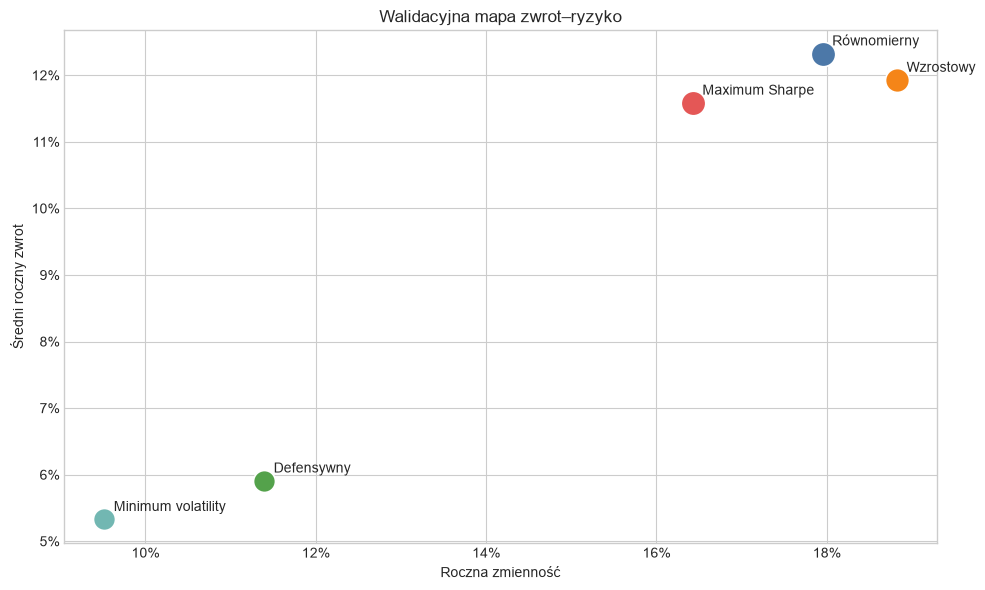

In [7]:
plot_data = validation_summary[
    [
        "scenario",
        "annualized_volatility",
        "annualized_mean_return",
        "sharpe_ratio",
    ]
].copy()
plot_scenarios = tuple(str(value) for value in plot_data["scenario"].tolist())
plot_volatilities = plot_data["annualized_volatility"].to_numpy(dtype=float)
plot_returns = plot_data["annualized_mean_return"].to_numpy(dtype=float)
plot_sharpe_ratios = plot_data["sharpe_ratio"].to_numpy(dtype=float)

figure, axis = plt.subplots(figsize=(10, 6))
for scenario, volatility_value, return_value, sharpe_value in zip(
    plot_scenarios,
    plot_volatilities,
    plot_returns,
    plot_sharpe_ratios,
    strict=True,
):
    volatility = float(volatility_value)
    annualized_return = float(return_value)
    sharpe_ratio = float(sharpe_value)
    axis.scatter(
        volatility,
        annualized_return,
        s=160 + max(sharpe_ratio, 0.0) * 260,
        color=scenario_colors[scenario],
        edgecolor="white",
        linewidth=1.2,
    )
    axis.annotate(
        scenario_labels[scenario],
        (volatility, annualized_return),
        xytext=(7, 6),
        textcoords="offset points",
    )
axis.set_xlabel("Roczna zmienność")
axis.set_ylabel("Średni roczny zwrot")
axis.set_title("Walidacyjna mapa zwrot–ryzyko")
axis.xaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
axis.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
figure.tight_layout()
plt.show()

## Wielowymiarowy profil ryzyka

Sharpe i Sortino opisują jakość zwrotu, a CVaR oraz maximum drawdown
pokazują odpowiednio ryzyko ogonowe i historyczną głębokość strat.


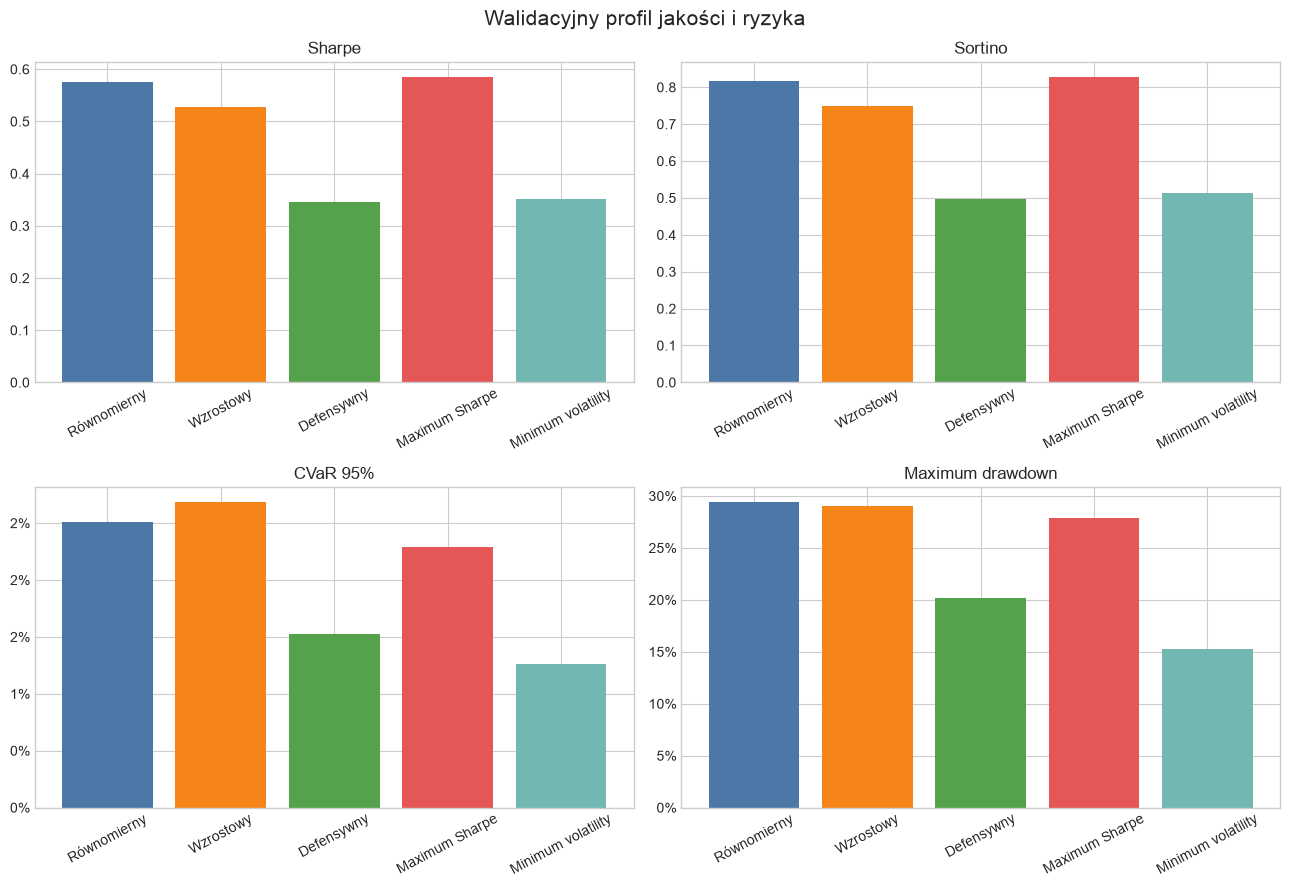

In [8]:
dashboard_metrics = [
    ("sharpe_ratio", "Sharpe", False),
    ("sortino_ratio", "Sortino", False),
    ("conditional_value_at_risk", "CVaR 95%", True),
    ("maximum_drawdown", "Maximum drawdown", True),
]
ordered_validation = validation_summary.set_index("scenario").loc[scenario_order]
figure, axes = plt.subplots(2, 2, figsize=(13, 9))
for axis, (column, title, percentage) in zip(
    axes.ravel(), dashboard_metrics, strict=True
):
    axis.bar(
        [scenario_labels[name] for name in scenario_order],
        ordered_validation[column],
        color=[scenario_colors[name] for name in scenario_order],
    )
    axis.set_title(title)
    axis.tick_params(axis="x", rotation=28)
    if percentage:
        axis.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
figure.suptitle("Walidacyjny profil jakości i ryzyka", fontsize=15)
figure.tight_layout()
plt.show()

## Struktura wag

Wagi ujawniają koncentrację i ekonomiczne źródło wyniku każdego
scenariusza.


In [9]:
weights_table = (
    weights.pivot(index="scenario", columns="ticker", values="weight")
    .loc[scenario_order]
    .fillna(0.0)
)
weights_display = weights_table.copy()
weights_display.index = [scenario_labels[name] for name in weights_display.index]
print(weights_display.to_string(float_format=lambda value: f"{value:.3f}"))

ticker               AGG  BTC-USD  EPOL   GLD   QQQ   SPY   VGK    VT
Równomierny        0.125    0.125 0.125 0.125 0.125 0.125 0.125 0.125
Wzrostowy          0.100    0.100 0.100 0.050 0.200 0.200 0.100 0.150
Defensywny         0.350    0.030 0.050 0.200 0.070 0.100 0.080 0.120
Maximum Sharpe     0.330    0.161 0.000 0.159 0.350 0.000 0.000 0.000
Minimum volatility 0.350    0.000 0.000 0.350 0.000 0.295 0.005 0.000


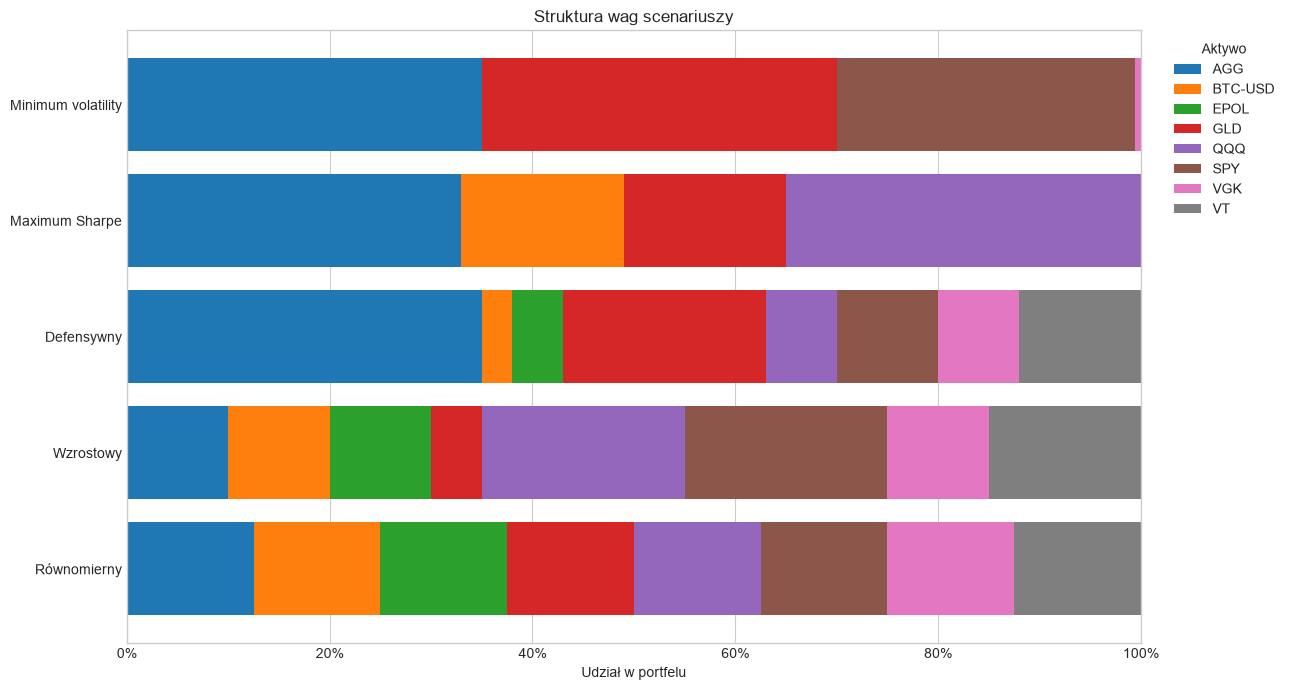

In [10]:
figure, axis = plt.subplots(figsize=(13, 7))
left = np.zeros(len(weights_table))
for ticker in weights_table.columns:
    ticker_weights = weights_table[ticker].to_numpy(dtype=float)
    axis.barh(
        [scenario_labels[name] for name in scenario_order],
        ticker_weights,
        left=left,
        label=ticker,
    )
    left += ticker_weights
axis.set_xlim(0.0, 1.0)
axis.set_xlabel("Udział w portfelu")
axis.set_title("Struktura wag scenariuszy")
axis.xaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
axis.legend(title="Aktywo", bbox_to_anchor=(1.02, 1.0))
figure.tight_layout()
plt.show()

## Wkłady aktywów

Waga nie jest tym samym co wpływ. Wkłady pokazują udział aktywów w
rocznym zwrocie i rocznej zmienności na walidacji.


In [11]:
validation_contributions = contributions.loc[contributions["split"] == "validation"]
return_contributions = (
    validation_contributions.pivot(
        index="scenario",
        columns="ticker",
        values="annualized_return_contribution",
    )
    .loc[scenario_order]
    .fillna(0.0)
)
volatility_contributions = (
    validation_contributions.pivot(
        index="scenario",
        columns="ticker",
        values="annualized_volatility_contribution",
    )
    .loc[scenario_order]
    .fillna(0.0)
)
contribution_check = pd.DataFrame(
    {
        "zwrot": return_contributions.sum(axis=1),
        "zmiennosc": volatility_contributions.sum(axis=1),
    }
)
print(contribution_check.to_string(float_format=lambda x: f"{x:.6f}"))

                      zwrot  zmiennosc
scenario                              
equal_weight       0.123225   0.179497
growth             0.119256   0.188226
defensive          0.059070   0.113919
maximum_sharpe     0.115829   0.164253
minimum_volatility 0.053289   0.095139


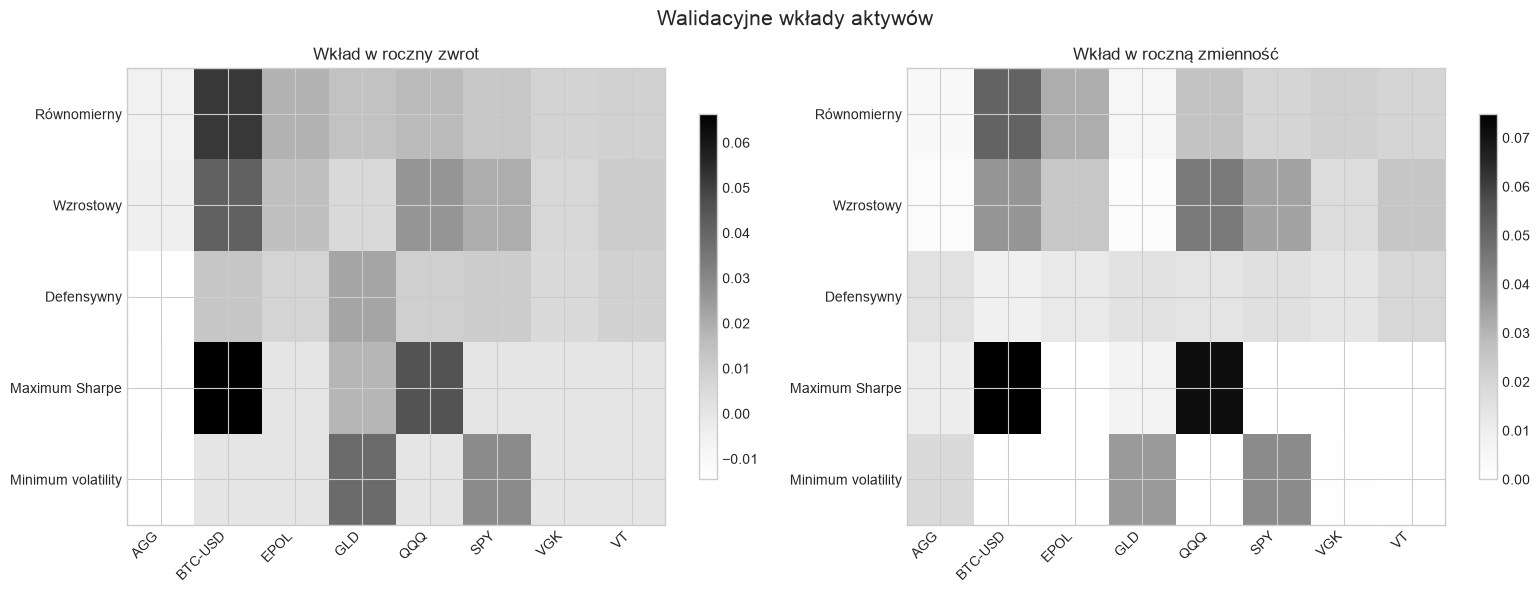

In [12]:
figure, axes = plt.subplots(1, 2, figsize=(16, 6))
panels = (
    (return_contributions, "Wkład w roczny zwrot"),
    (volatility_contributions, "Wkład w roczną zmienność"),
)
for axis, (matrix, title) in zip(axes, panels, strict=True):
    image = axis.imshow(matrix.to_numpy(dtype=float), aspect="auto")
    axis.set_xticks(range(len(matrix.columns)))
    axis.set_xticklabels(matrix.columns, rotation=45, ha="right")
    axis.set_yticks(range(len(matrix.index)))
    axis.set_yticklabels([scenario_labels[name] for name in matrix.index])
    axis.set_title(title)
    figure.colorbar(image, ax=axis, shrink=0.8)
figure.suptitle("Walidacyjne wkłady aktywów", fontsize=15)
figure.tight_layout()
plt.show()

## Zależności między aktywami

Porównanie korelacji pokazuje, czy potencjał dywersyfikacji zmienił się
po przejściu z treningu na walidację.


In [13]:
training_covariance_values = training_covariance.to_numpy(dtype=float)
validation_covariance_values = validation_covariance.to_numpy(dtype=float)
correlation_change = validation_correlation - training_correlation
print(
    "Najmniejsza wartość własna kowariancji — trening: "
    f"{np.linalg.eigvalsh(training_covariance_values).min():.10f}"
)
print(
    "Najmniejsza wartość własna kowariancji — walidacja: "
    f"{np.linalg.eigvalsh(validation_covariance_values).min():.10f}"
)

Najmniejsza wartość własna kowariancji — trening: 0.0003343332
Najmniejsza wartość własna kowariancji — walidacja: 0.0002968476


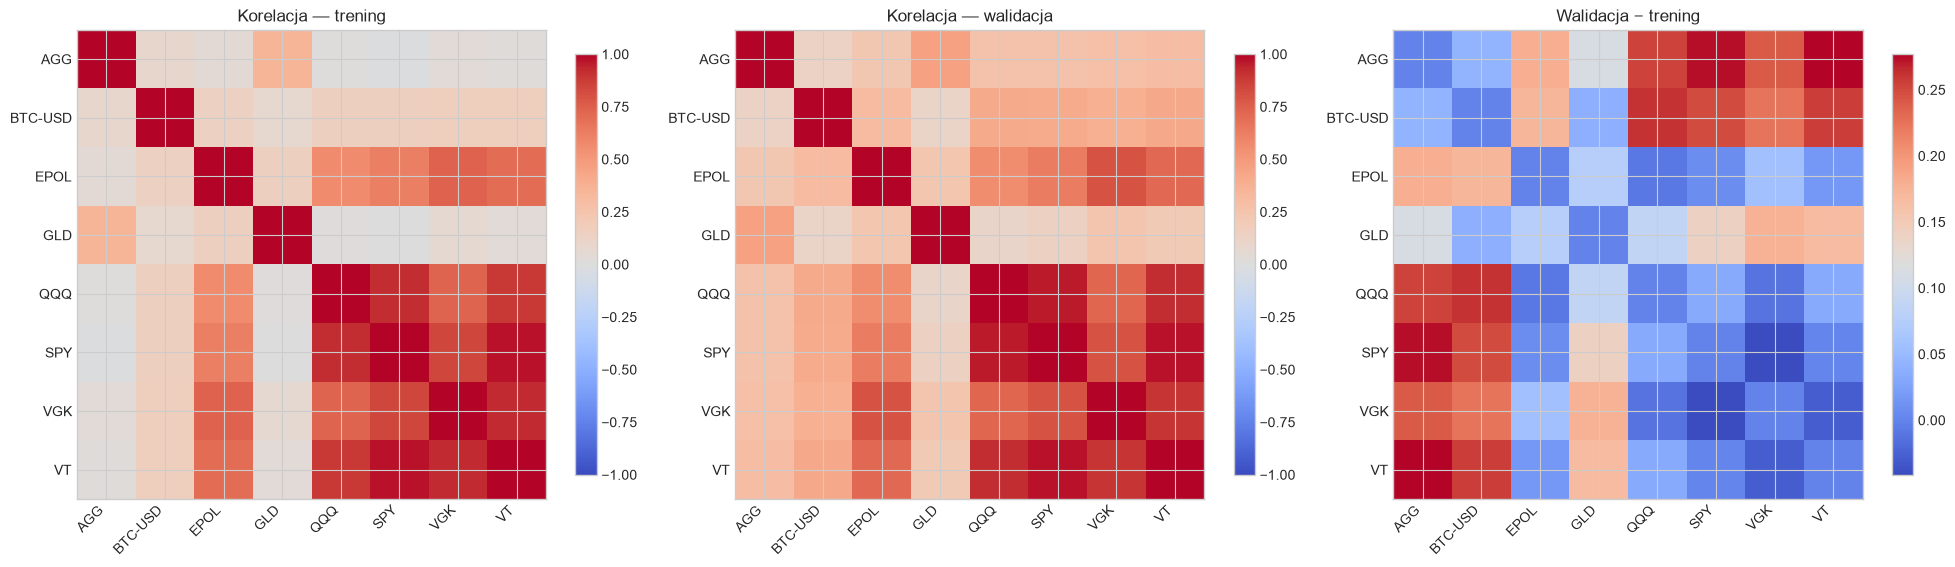

In [14]:
correlation_panels = (
    (training_correlation, "Korelacja — trening", -1.0, 1.0),
    (validation_correlation, "Korelacja — walidacja", -1.0, 1.0),
    (correlation_change, "Walidacja − trening", None, None),
)
figure, axes = plt.subplots(1, 3, figsize=(20, 6))
for axis, (matrix, title, lower, upper) in zip(axes, correlation_panels, strict=True):
    image = axis.imshow(
        matrix.to_numpy(dtype=float),
        cmap="coolwarm",
        vmin=lower,
        vmax=upper,
    )
    axis.set_xticks(range(len(matrix.columns)))
    axis.set_xticklabels(matrix.columns, rotation=45, ha="right")
    axis.set_yticks(range(len(matrix.index)))
    axis.set_yticklabels(matrix.index)
    axis.set_title(title)
    figure.colorbar(image, ax=axis, shrink=0.75)
figure.tight_layout()
plt.show()

## Ścieżki portfeli na walidacji

Skumulowane zwroty i drawdown pokazują przebieg wyników, którego nie
widać w pojedynczej wartości metryki.


In [15]:
validation_returns = (
    portfolio_returns.loc[portfolio_returns["split"] == "validation"]
    .pivot(
        index="date",
        columns="scenario",
        values="portfolio_return",
    )
    .sort_index()
    .loc[:, scenario_order]
)
assert not validation_returns.isna().any().any()
cumulative_returns = (1.0 + validation_returns).cumprod() - 1.0
wealth_index = 1.0 + cumulative_returns
drawdowns = wealth_index / wealth_index.cummax() - 1.0
diagnostics = pd.DataFrame(
    {
        "obserwacje": validation_returns.count(),
        "zwrot_skumulowany": cumulative_returns.iloc[-1],
        "maximum_drawdown": -drawdowns.min(),
    }
)
print(diagnostics.to_string(float_format=lambda x: f"{x:.6f}"))

                    obserwacje  zwrot_skumulowany  maximum_drawdown
scenario                                                           
equal_weight               565           0.271396          0.293717
growth                     565           0.255619          0.290784
defensive                  565           0.125145          0.201561
maximum_sharpe             565           0.257841          0.278606
minimum_volatility         565           0.115551          0.153050


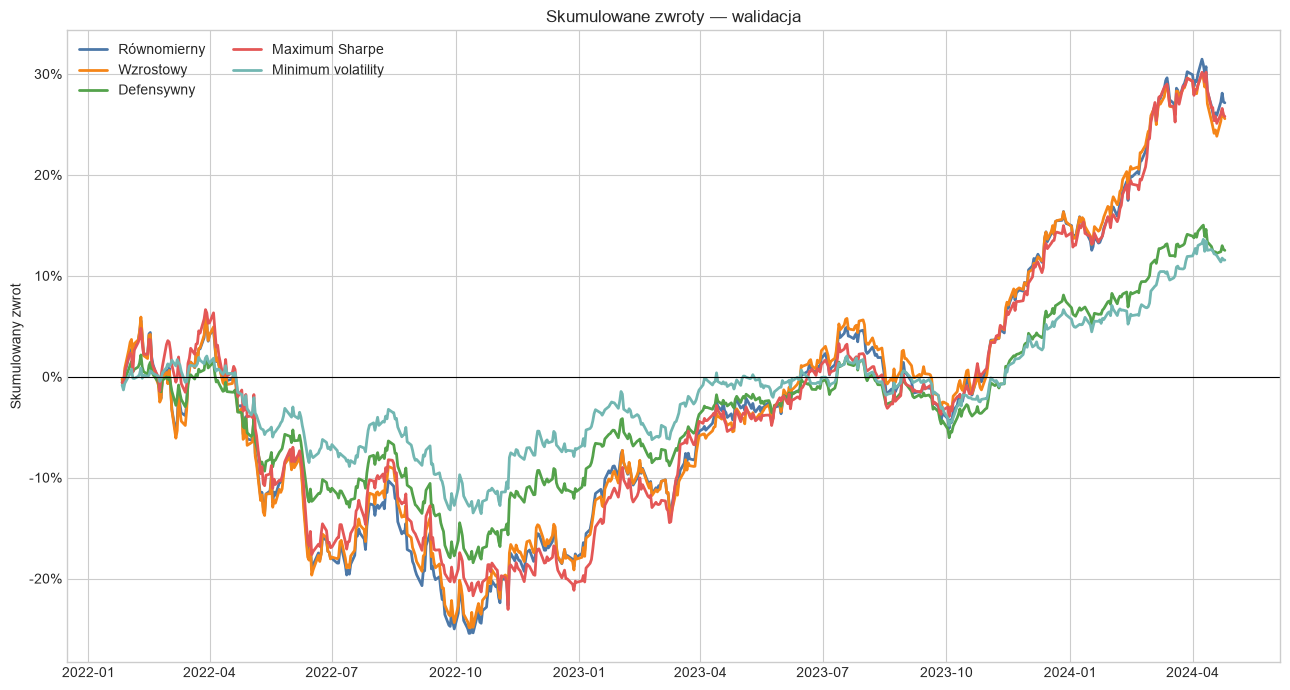

In [16]:
figure, axis = plt.subplots(figsize=(13, 7))
for scenario in scenario_order:
    axis.plot(
        cumulative_returns.index,
        cumulative_returns[scenario],
        label=scenario_labels[scenario],
        color=scenario_colors[scenario],
        linewidth=2.0,
    )
axis.axhline(0.0, color="black", linewidth=0.8)
axis.set_ylabel("Skumulowany zwrot")
axis.set_title("Skumulowane zwroty — walidacja")
axis.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
axis.legend(ncol=2)
figure.tight_layout()
plt.show()

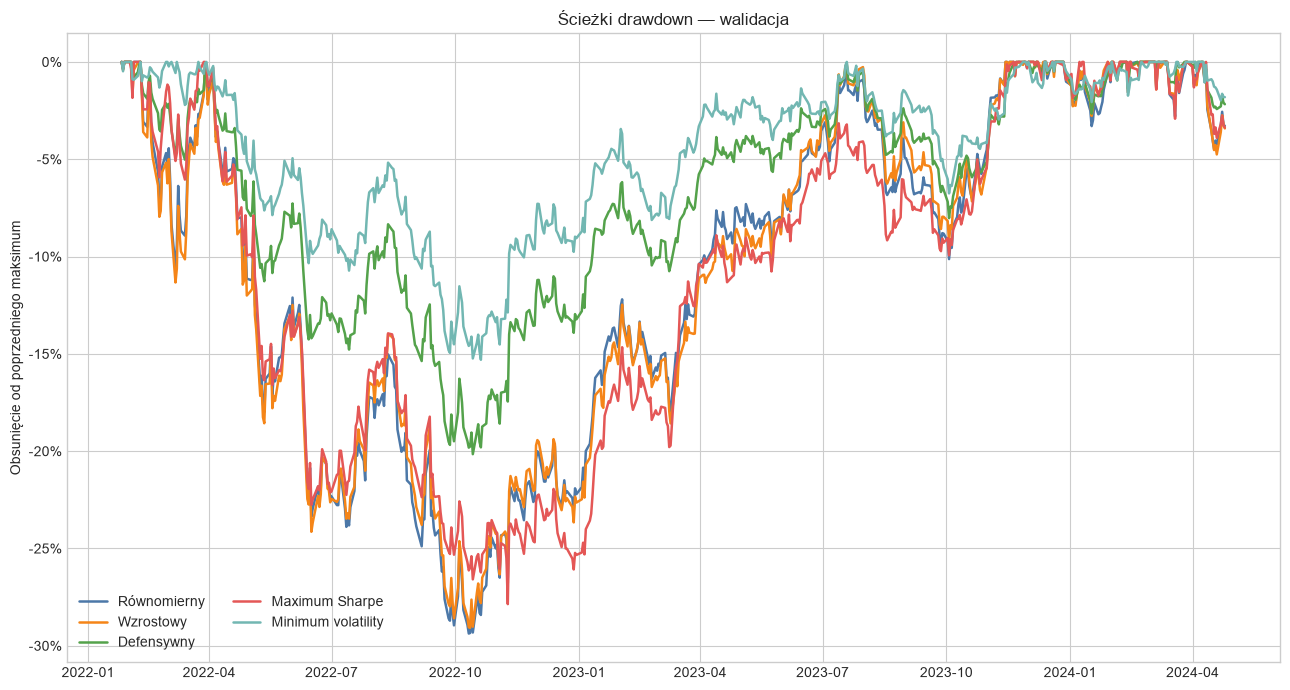

In [17]:
figure, axis = plt.subplots(figsize=(13, 7))
for scenario in scenario_order:
    axis.plot(
        drawdowns.index,
        drawdowns[scenario],
        label=scenario_labels[scenario],
        color=scenario_colors[scenario],
        linewidth=1.8,
    )
axis.set_ylabel("Obsunięcie od poprzedniego maksimum")
axis.set_title("Ścieżki drawdown — walidacja")
axis.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
axis.legend(ncol=2)
figure.tight_layout()
plt.show()

## Stabilność trening–walidacja

Różnica między okresami ujawnia zmianę reżimu oraz optymizm estymacji
treningowej. Decyzje należy opierać na jakości poza próbą.


In [18]:
generalization = summary.pivot(
    index="scenario",
    columns="split",
    values=["sharpe_ratio", "annualized_volatility"],
)
generalization.columns = [
    f"{metric}_{split_name}" for metric, split_name in generalization.columns
]
generalization = generalization.loc[scenario_order]
generalization["sharpe_change"] = (
    generalization["sharpe_ratio_validation"] - generalization["sharpe_ratio_training"]
)
generalization["volatility_change"] = (
    generalization["annualized_volatility_validation"]
    - generalization["annualized_volatility_training"]
)
generalization_display = generalization.copy()
generalization_display.index = [
    scenario_labels[name] for name in generalization_display.index
]
print(generalization_display.to_string(float_format=lambda value: f"{value:.6f}"))

                    sharpe_ratio_training  sharpe_ratio_validation  annualized_volatility_training  annualized_volatility_validation  sharpe_change  volatility_change
Równomierny                      1.096285                 0.576176                        0.159751                          0.179497      -0.520109           0.019745
Wzrostowy                        1.058401                 0.528367                        0.164445                          0.188226      -0.530033           0.023781
Defensywny                       0.872392                 0.344690                        0.091043                          0.113919      -0.527702           0.022876
Maximum Sharpe                   1.432372                 0.584621                        0.152984                          0.164253      -0.847751           0.011269
Minimum volatility               0.726117                 0.351968                        0.076965                          0.095139      -0.374149           0.01817

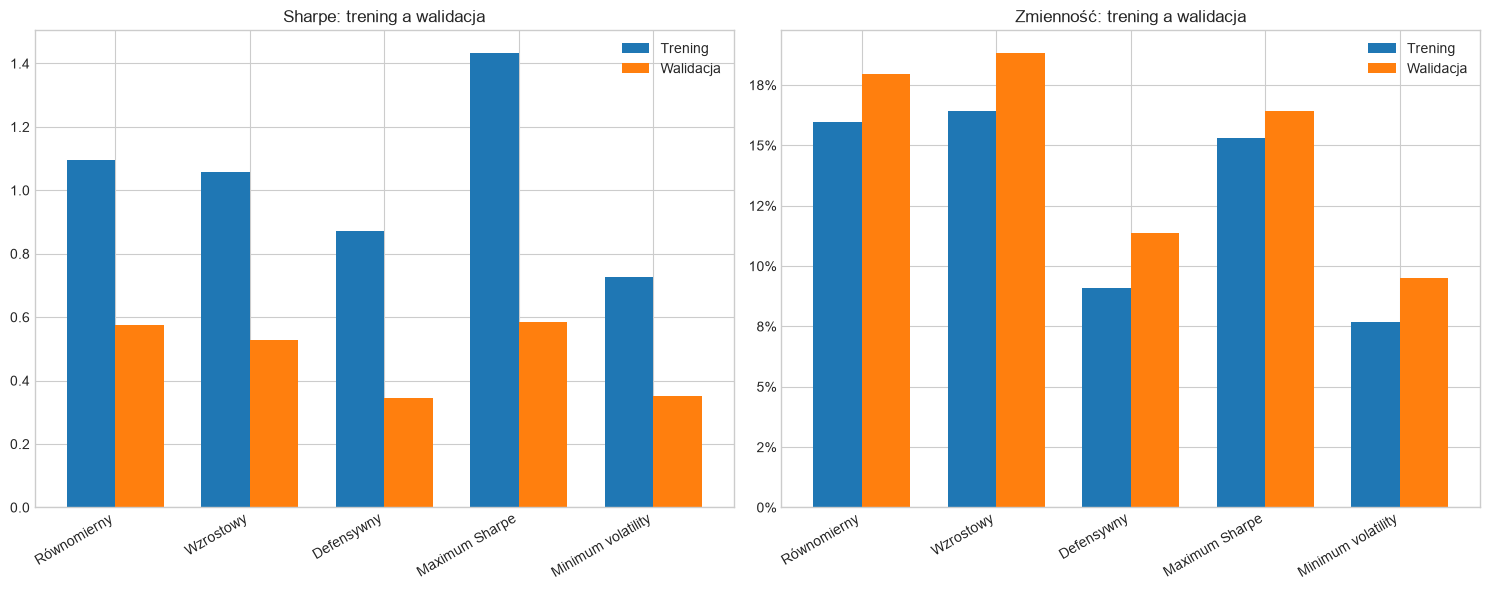

In [19]:
figure, axes = plt.subplots(1, 2, figsize=(15, 6))
positions = np.arange(len(scenario_order))
width = 0.36
labels = [scenario_labels[name] for name in scenario_order]
panels = (
    ("sharpe_ratio", "Sharpe: trening a walidacja", False),
    (
        "annualized_volatility",
        "Zmienność: trening a walidacja",
        True,
    ),
)
for axis, (metric, title, percentage) in zip(axes, panels, strict=True):
    axis.bar(
        positions - width / 2,
        generalization[f"{metric}_training"],
        width,
        label="Trening",
    )
    axis.bar(
        positions + width / 2,
        generalization[f"{metric}_validation"],
        width,
        label="Walidacja",
    )
    axis.set_title(title)
    axis.set_xticks(positions)
    axis.set_xticklabels(labels, rotation=30, ha="right")
    axis.legend()
    if percentage:
        axis.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
figure.tight_layout()
plt.show()

## Najważniejsze wyniki

Wnioski są wyprowadzane z walidacji, nie z dopasowania treningowego.


In [20]:
scenario_names = np.asarray(
    validation_summary["scenario"].astype(str).tolist(),
    dtype=str,
)

sharpe_values = np.asarray(
    validation_summary["sharpe_ratio"].tolist(),
    dtype=np.float64,
)

volatility_values = np.asarray(
    validation_summary["annualized_volatility"].tolist(),
    dtype=np.float64,
)

drawdown_values = np.asarray(
    validation_summary["maximum_drawdown"].tolist(),
    dtype=np.float64,
)

best_sharpe_position = int(np.nanargmax(sharpe_values))

lowest_volatility_position = int(np.nanargmin(volatility_values))

lowest_drawdown_position = int(np.nanargmin(drawdown_values))

best_sharpe = str(scenario_names[best_sharpe_position])

lowest_volatility = str(scenario_names[lowest_volatility_position])

lowest_drawdown = str(scenario_names[lowest_drawdown_position])

equal_weight_positions = np.flatnonzero(scenario_names == "equal_weight")

minimum_volatility_positions = np.flatnonzero(scenario_names == "minimum_volatility")

if len(equal_weight_positions) != 1:
    raise ValueError("Expected exactly one equal_weight scenario.")

if len(minimum_volatility_positions) != 1:
    raise ValueError("Expected exactly one minimum_volatility scenario.")

equal_weight_position = int(equal_weight_positions[0])

minimum_volatility_position = int(minimum_volatility_positions[0])

equal_weight_volatility = float(volatility_values[equal_weight_position])

minimum_volatility_value = float(volatility_values[minimum_volatility_position])

equal_weight_drawdown = float(drawdown_values[equal_weight_position])

minimum_volatility_drawdown = float(drawdown_values[minimum_volatility_position])

volatility_reduction = 1.0 - (minimum_volatility_value / equal_weight_volatility)

drawdown_reduction = 1.0 - (minimum_volatility_drawdown / equal_weight_drawdown)

print(f"Najwyższy Sharpe: {scenario_labels[best_sharpe]}")

print(f"Najniższa zmienność: {scenario_labels[lowest_volatility]}")

print(f"Najniższy drawdown: {scenario_labels[lowest_drawdown]}")

print(f"Redukcja zmienności: {volatility_reduction:.2%}")

print(f"Redukcja drawdown: {drawdown_reduction:.2%}")

Najwyższy Sharpe: Maximum Sharpe
Najniższa zmienność: Minimum volatility
Najniższy drawdown: Minimum volatility
Redukcja zmienności: 47.00%
Redukcja drawdown: 47.89%


## Ograniczenia

Wyniki historyczne nie gwarantują przyszłych rezultatów. Estymacje
zwrotów i kowariancji zależą od reżimu, Maximum Sharpe jest wrażliwy na
oczekiwane zwroty, a analiza nie uwzględnia kosztów i podatków. System
wspiera decyzję, ale nie stanowi automatycznej rekomendacji.

Końcowy zbiór testowy pozostaje zamknięty do jednokrotnej oceny
wybranego rozwiązania.


In [21]:
validation_metrics = validation_summary.set_index("scenario").reindex(scenario_order)

expected_annualized_returns = np.asarray(
    validation_metrics["annualized_mean_return"].tolist(),
    dtype=np.float64,
)

expected_annualized_volatility = np.asarray(
    validation_metrics["annualized_volatility"].tolist(),
    dtype=np.float64,
)

return_contribution_values = np.asarray(
    return_contributions.sum(axis=1),
    dtype=np.float64,
)

volatility_contribution_values = np.asarray(
    volatility_contributions.sum(axis=1),
    dtype=np.float64,
)

assert np.allclose(
    return_contribution_values,
    expected_annualized_returns,
)

assert np.allclose(
    volatility_contribution_values,
    expected_annualized_volatility,
)

assert np.linalg.eigvalsh(training_covariance_values).min() >= -1e-12

assert np.linalg.eigvalsh(validation_covariance_values).min() >= -1e-12

assert validation_returns.shape == (
    565,
    5,
)

assert best_sharpe == "maximum_sharpe"

assert lowest_volatility == "minimum_volatility"

assert lowest_drawdown == "minimum_volatility"

print("Integralność analizy ryzyka i portfeli: OK")

print("Wagi wyznaczone wyłącznie na treningu: OK")

print("Ocena scenariuszy na walidacji: OK")

print("Końcowy zbiór testowy pozostaje zamknięty: OK")

print("Notebook 03 wykonany poprawnie: OK")

Integralność analizy ryzyka i portfeli: OK
Wagi wyznaczone wyłącznie na treningu: OK
Ocena scenariuszy na walidacji: OK
Końcowy zbiór testowy pozostaje zamknięty: OK
Notebook 03 wykonany poprawnie: OK
